# ♟️ Chess Numba — Phase 7 Colab SPSA（History Damping & Deep-LMR Divisor）

本 Notebook 執行 **Phase 7**：在 Plan A 生產基線（`1ed92f0`）上，對「失敗安靜步懲罰衰減 + 深層 LMR 除數」做精修。
計畫書：`chess_engine/classical/PHASE7_HISTORY_LMR_ALIGNMENT_PLAN.md`

### 🎯 四個 SPSA 軸（全為 `SearchContext.tune[]` 運行時槽位，免重編譯）
| 參數 | 基線 | 範圍 | 步長 c | tune 槽位 |
| :-- | --: | :-: | --: | --: |
| `HISTORY_QUIET_MALUS_DECAY_NUM` | 956 | [880, 1000] | 8 | 39 |
| `HISTORY_MALUS_CAP` | 1600 | [1200, 2000] | 50 | 36 |
| `LMR_DIVISOR_DEPTH_STEP` | 128 | [0, 256] | 16 | 40 |
| `HISTORY_QUIET_MALUS_SCALE_NUM` | 1024 | [768, 1280] | 32 | 41 |

> `HISTORY_REFUTE_SCALE_NUM` 已從計畫剔除：搜尋程式碼中它是**死常數**（refutation malus 直接用 `malus`），調它沒有任何效果。
> `LMR_DIVISOR_MIN_DEPTH` 固定為 10（與 `DEPTH_STEP` 構成同一條斜坡，兩者同調不可辨識）。

### ⚡ 流程
1. **L1 SPSA**：`40` 輪 × `200` 局 @ `200,000` nodes（`inprocess` 單次 JIT，Polyak tail 0.3 取樣）
2. **L2 驗收**：600+ 局 @ 300,000 nodes，TT 64MB，**對手 = 目前 Plan A 基線**（非 `classical_old`），SPRT(0, 3)
3. **（選）單軸消融**：確認增益不是單一軸的巧合

### 💾 斷線保護
Colab 單次 session 有時間上限；狀態與日誌預設存到 **Google Drive**，斷線後重跑本 Notebook 即自動 `--resume`。
**注意**：續跑時 `GAMES / NODES / CONCURRENCY / TOTAL_ITERS / SPSA_A_RATIO / PARAMS` 必須與第一次完全相同。

In [1]:
# 1. 檢視 Colab 硬體
!lscpu | grep "Model name\|Socket\|Thread\|NUMA\|CPU(s)"
!python3 --version

CPU(s):                                  8
On-line CPU(s) list:                     0-7
Model name:                              AMD EPYC 7B12
Thread(s) per core:                      2
Socket(s):                               1
NUMA node(s):                            1
NUMA node0 CPU(s):                       0-7
Python 3.13.16


In [2]:
# 2. 設定（續跑時請勿更動 PARAMS / GAMES / NODES / CONCURRENCY / TOTAL_ITERS / SPSA_A_RATIO）
REPO_URL = "https://github.com/b08203031/chess_numba.git"
BRANCH = "feat-initial-bitboard-setup"
RUN_TAG = "history_p7_l1"

PARAMS = [
    "HISTORY_QUIET_MALUS_DECAY_NUM",
    "HISTORY_MALUS_CAP",
    "LMR_DIVISOR_DEPTH_STEP",
    "HISTORY_QUIET_MALUS_SCALE_NUM",
]

# ---- L1 SPSA ----
NODES = 200000            # 100k 看不到深層 LMR 除數（depth>10 才啟動）；越高越能調 DEPTH_STEP，但越慢
GAMES = 200            # 每輪 plus/minus 對局數
TOTAL_ITERS = 40      # 整個 campaign 計畫輪數（decay 時程以此為準）
CHUNK_ITERS = TOTAL_ITERS  # 每次執行最多跑幾輪（想分段跑可調小，例如 12）
TT_MB = 32
SPSA_A_RATIO = 0.2
CONCURRENCY = 7            # 8 vCPU -> 7；續跑必須相同
TAIL = 0.3                 # Polyak-Ruppert 尾端比例

# ---- L2 驗收 ----
L2_NODES = 300000
L2_GAMES = 1000
L2_TT_MB = 64

USE_DRIVE = True           # 狀態/日誌/候選存到 Google Drive
RUN_SMOKE = True           # 第一次建議先跑 8 局冒煙（驗證指令與 JIT）

In [3]:
# 3. 持久化目錄（Google Drive）
import os
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PERSIST = "/content/drive/MyDrive/chess_numba_p7"
else:
    PERSIST = "/content/chess_numba_p7_persist"

for sub in ("states", "logs", "results"):
    os.makedirs(f"{PERSIST}/{sub}", exist_ok=True)

STATE_FILE = f"{PERSIST}/states/{RUN_TAG}.json"
LOG_FILE = f"{PERSIST}/logs/{RUN_TAG}.jsonl"
CAND_UNIFORM = f"{PERSIST}/results/candidate_p7_tail_uniform.json"
CAND_LINEAR = f"{PERSIST}/results/candidate_p7_tail_linear.json"
print("persist dir:", PERSIST)
print("state:", STATE_FILE)
print("log  :", LOG_FILE)

Mounted at /content/drive
persist dir: /content/drive/MyDrive/chess_numba_p7
state: /content/drive/MyDrive/chess_numba_p7/states/history_p7_l1.json
log  : /content/drive/MyDrive/chess_numba_p7/logs/history_p7_l1.jsonl


In [4]:
# 4. 取得最新程式碼（需先把 Step 1 的 tune 槽位改動 commit + push 到 BRANCH）
import os
if not os.path.exists("/content/chess_numba"):
    %cd /content
    !git clone -b {BRANCH} {REPO_URL}

%cd /content/chess_numba
!git fetch origin {BRANCH}
!git checkout -f {BRANCH}
!git reset --hard origin/{BRANCH}
!pip install -q numba chess numpy matplotlib
!git log -1 --oneline

/content
Cloning into 'chess_numba'...
remote: Enumerating objects: 3602, done.
remote: Counting objects: 100% (340/340), done.
remote: Compressing objects: 100% (198/198), done.
remote: Total 3602 (delta 252), reused 215 (delta 142), pack-reused 3262 (from 1)
Receiving objects: 100% (3602/3602), 176.00 MiB | 28.87 MiB/s, done.
Resolving deltas: 100% (2475/2475), done.
/content/chess_numba
From https://github.com/b08203031/chess_numba
 * branch            feat-initial-bitboard-setup -> FETCH_HEAD
Already on 'feat-initial-bitboard-setup'
Your branch is up to date with 'origin/feat-initial-bitboard-setup'.
HEAD is now at 3e59cc0 feat(tune): expand SearchContext.tune to 42 slots and prepare Phase 7 Colab runner
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 19.2 MB/s eta 0:00:0000:0100:01
  Preparing metadata (setup.py) ... done
3e59cc0 (HEAD -> feat-initial-bitboard-setup, origin/feat-initial-bitboard-setup, origin/HEAD) feat(tune): expand SearchContext.tune to 42 slots and pre

In [5]:
# 5. 驗證程式碼版本與 Phase 7 基線（Plan A）
import sys, json
sys.path.insert(0, "/content/chess_numba")
from chess_engine.classical import constants as C
from tune_search.search_param_registry import get_default_params, get_spec

assert C.TUNE_SIZE == 42, f"TUNE_SIZE={C.TUNE_SIZE}; 請確認已 push Step 1 的槽位改動（需為 42）"

expected_plan_a = {
    "HISTORY_QUIET_MALUS_DECAY_NUM": 956,
    "HISTORY_MALUS_CAP": 1600,
    "LMR_DIVISOR_DEPTH_STEP": 128,
    "HISTORY_QUIET_MALUS_SCALE_NUM": 1024,
}
baseline = get_default_params(PARAMS)
assert baseline == expected_plan_a, f"基線與 Plan A 不一致！{baseline} vs {expected_plan_a}"

BASELINE_JSON = "/content/chess_numba/tune_search/baseline_history_p7.json"
with open(BASELINE_JSON, "w", encoding="utf-8") as f:
    json.dump(baseline, f, indent=2)

print(f"{'param':34s} {'default':>8s} {'range':>14s} {'c':>5s} {'slot':>5s}")
for name in PARAMS:
    s = get_spec(name)
    print(f"{name:34s} {s.default:8d} {'['+str(s.minimum)+','+str(s.maximum)+']':>14s} {s.step:5d} {s.runtime_index:5d}")
print("✅ Plan A 基線驗證通過；基線檔:", BASELINE_JSON)

param                               default          range     c  slot
HISTORY_QUIET_MALUS_DECAY_NUM           956     [880,1000]     8    39
HISTORY_MALUS_CAP                      1600    [1200,2000]    50    36
LMR_DIVISOR_DEPTH_STEP                  128        [0,256]    16    40
HISTORY_QUIET_MALUS_SCALE_NUM          1024     [768,1280]    32    41
✅ Plan A 基線驗證通過；基線檔: /content/chess_numba/tune_search/baseline_history_p7.json


In [6]:
# 6. 冒煙測試（8 局 @ 20k nodes；首次含 JIT 編譯，可能數分鐘，請耐心等候勿重啟）
if RUN_SMOKE:
    !python -m tune_search.search_tuner \
      --params {",".join(PARAMS)} \
      --backend inprocess --scale-mode integer \
      --iter 1 --games 8 --nodes 20000 \
      --spsa-a-ratio {SPSA_A_RATIO} --concurrency {CONCURRENCY} \
      --adjudicate --log /tmp/p7_smoke.jsonl --state ''
else:
    print("RUN_SMOKE=False，略過。")

[inprocess] openings=500 nodes=20000 concurrency=7 tt=16MB
[pool] allocate worker pair 1/7 (tt=16MB)...
[pool] allocate worker pair 2/7 (tt=16MB)...
[pool] allocate worker pair 3/7 (tt=16MB)...
[pool] allocate worker pair 4/7 (tt=16MB)...
[pool] allocate worker pair 5/7 (tt=16MB)...
[pool] allocate worker pair 6/7 (tt=16MB)...
[pool] allocate worker pair 7/7 (tt=16MB)...
[warmup] JIT nodes=5000 (may take several minutes first time)...
[warmup] done in 1.0s
[warmup] JIT nodes=1500 (may take several minutes first time)...
[warmup] done in 0.0s
[inprocess] touch worker 2/7
[warmup] JIT nodes=800 (may take several minutes first time)...
[warmup] done in 0.0s
[warmup] JIT nodes=800 (may take several minutes first time)...
[warmup] done in 0.0s
[inprocess] touch worker 3/7
[warmup] JIT nodes=800 (may take several minutes first time)...
[warmup] done in 0.0s
[warmup] JIT nodes=800 (may take several minutes first time)...
[warmup] done in 0.0s
[inprocess] touch worker 4/7
[warmup] JIT nodes=80

In [ ]:
# 7. L1 SPSA 主調參（自動斷點續跑；一律傳 --schedule-iterations 以固定衰減時程）
import os, json

done_iters = 0
if os.path.exists(STATE_FILE):
    with open(STATE_FILE, "r", encoding="utf-8") as f:
        done_iters = int(json.load(f).get("iteration", 0))
    resume_flag = "--resume"
else:
    resume_flag = ""

remaining = max(0, TOTAL_ITERS - done_iters)
run_now = min(remaining, CHUNK_ITERS)
print(f"已完成 {done_iters}/{TOTAL_ITERS} 輪；本次執行 {run_now} 輪（{'續跑' if resume_flag else '全新開跑'}）")
print(f"預估：{GAMES} 局 @ {NODES:,} nodes，約 {GAMES * 3.7 * NODES / 100000 / 60:.0f} 分鐘/輪（以 Phase 6 實測 3.7 s/局@100k、7 併發線性外推）")

if run_now > 0:
    !python -m tune_search.search_tuner \
      --params {",".join(PARAMS)} \
      --backend inprocess --scale-mode integer \
      --iter {run_now} --schedule-iterations {TOTAL_ITERS} \
      --games {GAMES} --nodes {NODES} --tt-mb {TT_MB} \
      --spsa-a-ratio {SPSA_A_RATIO} --concurrency {CONCURRENCY} \
      --adjudicate \
      --log {LOG_FILE} --state {STATE_FILE} {resume_flag}
else:
    print("✅ L1 全部輪數已完成，請繼續執行下一個 cell。")

已完成 0/40 輪；本次執行 40 輪（全新開跑）
預估：200 局 @ 200,000 nodes，約 25 分鐘/輪（以 Phase 6 實測 3.7 s/局@100k、7 併發線性外推）
[inprocess] openings=500 nodes=200000 concurrency=7 tt=32MB
[pool] allocate worker pair 1/7 (tt=32MB)...
[pool] allocate worker pair 2/7 (tt=32MB)...
[pool] allocate worker pair 3/7 (tt=32MB)...
[pool] allocate worker pair 4/7 (tt=32MB)...
[pool] allocate worker pair 5/7 (tt=32MB)...
[pool] allocate worker pair 6/7 (tt=32MB)...
[pool] allocate worker pair 7/7 (tt=32MB)...
[warmup] JIT nodes=5000 (may take several minutes first time)...
[warmup] done in 0.9s
[warmup] JIT nodes=1500 (may take several minutes first time)...
[warmup] done in 0.0s
[inprocess] touch worker 2/7
[warmup] JIT nodes=800 (may take several minutes first time)...
[warmup] done in 0.0s
[warmup] JIT nodes=800 (may take several minutes first time)...
[warmup] done in 0.0s
[inprocess] touch worker 3/7
[warmup] JIT nodes=800 (may take several minutes first time)...
[warmup] done in 0.0s
[warmup] JIT nodes=800 (may take seve

已記錄 24 輪
最近 8 輪：
  iter  17  score_plus=0.520  signal=+0.020  {'HISTORY_MALUS_CAP': 1605, 'HISTORY_QUIET_MALUS_DECAY_NUM': 956, 'HISTORY_QUIET_MALUS_SCALE_NUM': 1031, 'LMR_DIVISOR_DEPTH_STEP': 135}
  iter  18  score_plus=0.522  signal=+0.022  {'HISTORY_MALUS_CAP': 1600, 'HISTORY_QUIET_MALUS_DECAY_NUM': 956, 'HISTORY_QUIET_MALUS_SCALE_NUM': 1034, 'LMR_DIVISOR_DEPTH_STEP': 133}
  iter  19  score_plus=0.485  signal=-0.015  {'HISTORY_MALUS_CAP': 1597, 'HISTORY_QUIET_MALUS_DECAY_NUM': 956, 'HISTORY_QUIET_MALUS_SCALE_NUM': 1032, 'LMR_DIVISOR_DEPTH_STEP': 134}
  iter  20  score_plus=0.483  signal=-0.017  {'HISTORY_MALUS_CAP': 1593, 'HISTORY_QUIET_MALUS_DECAY_NUM': 955, 'HISTORY_QUIET_MALUS_SCALE_NUM': 1030, 'LMR_DIVISOR_DEPTH_STEP': 133}
  iter  21  score_plus=0.495  signal=-0.005  {'HISTORY_MALUS_CAP': 1592, 'HISTORY_QUIET_MALUS_DECAY_NUM': 955, 'HISTORY_QUIET_MALUS_SCALE_NUM': 1030, 'LMR_DIVISOR_DEPTH_STEP': 133}
  iter  22  score_plus=0.490  signal=-0.010  {'HISTORY_MALUS_CAP': 1594, 'HIST

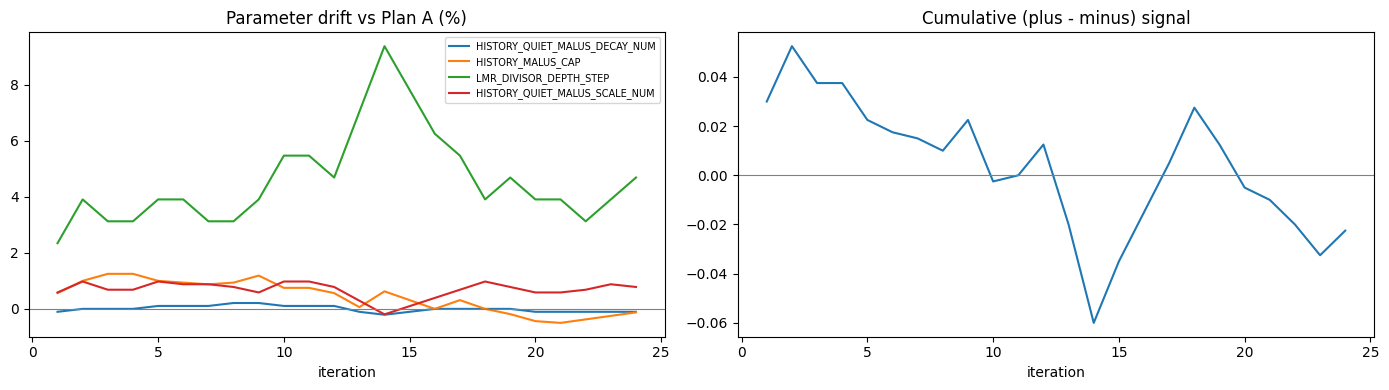

In [ ]:
# 8. 進度監控（可在 L1 執行中另開 cell 重複執行，或事後檢視）
import json, os
import matplotlib.pyplot as plt

rows = []
if os.path.exists(LOG_FILE):
    with open(LOG_FILE, "r", encoding="utf-8") as f:
        for line in f:
            rec = json.loads(line)
            if rec.get("event") == "iteration":
                rows.append(rec)

print(f"已記錄 {len(rows)} 輪")
if rows:
    cum = 0.0
    xs, cums = [], []
    for r in rows:
        cum += float(r["signal"])
        xs.append(r["iteration"]); cums.append(cum)
    print("最近 8 輪：")
    for r in rows[-8:]:
        print(f"  iter {r['iteration']:3d}  score_plus={r['score_plus']:.3f}  signal={r['signal']:+.3f}  {r['updated_params']}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for name in PARAMS:
        base = expected_plan_a[name]
        axes[0].plot([r["iteration"] for r in rows],
                     [100.0 * (r["updated_params"][name] - base) / base for r in rows], label=name)
    axes[0].axhline(0, color="gray", lw=0.8)
    axes[0].set_title("Parameter drift vs Plan A (%)"); axes[0].set_xlabel("iteration"); axes[0].legend(fontsize=7)
    axes[1].plot(xs, cums); axes[1].axhline(0, color="gray", lw=0.8)
    axes[1].set_title("Cumulative (plus - minus) signal"); axes[1].set_xlabel("iteration")
    plt.tight_layout(); plt.show()

In [ ]:
# 9. 產出候選參數（Polyak-Ruppert 尾端平均）
!python tune_search/summarize_run.py {LOG_FILE} --tail {TAIL} --weight-mode uniform --out {CAND_UNIFORM}
!python tune_search/summarize_run.py {LOG_FILE} --tail {TAIL} --weight-mode linear  --out {CAND_LINEAR}
print("\n=== uniform ===")
!cat {CAND_UNIFORM}
print("\n=== linear ===")
!cat {CAND_LINEAR}

iterations=24 games=4800 mean_score=0.4991
score sd observed=0.0186 noise-only expected=0.0232 ratio=0.80
  -> ratio ~1: batch scores are indistinguishable from sampling noise; this run carries (almost) no gradient signal. Use more games per batch / more batches before trusting any parameter movement.

param                             default      last  tail_avg moved%rng  drift_z
HISTORY_QUIET_MALUS_DECAY_NUM         956     955.1     955.4     -0.76    -0.25  (noise)
HISTORY_MALUS_CAP                    1600    1598.4    1595.7     -0.20    -0.07  (noise)
LMR_DIVISOR_DEPTH_STEP                128     133.7     133.3      2.24     0.80  (noise)
HISTORY_QUIET_MALUS_SCALE_NUM        1024    1031.8    1031.6      1.52     0.54  (noise)

averaged candidate (last 7 iterations, weight_mode=uniform):
--param HISTORY_QUIET_MALUS_DECAY_NUM=955 --param HISTORY_MALUS_CAP=1596 --param LMR_DIVISOR_DEPTH_STEP=133 --param HISTORY_QUIET_MALUS_SCALE_NUM=1032
wrote /content/drive/MyDrive/chess_numba_p

In [ ]:
# 10. 候選合理性檢查（避免重蹈 Phase 6：100k 調出的 MALUS_CAP 在 300k 退步）
import json
cand = json.load(open(CAND_UNIFORM, encoding="utf-8"))["averaged_params"]
print(f"{'param':34s} {'baseline':>9s} {'candidate':>10s} {'delta%':>8s}  note")
for name in PARAMS:
    s = get_spec(name)
    v = int(cand[name]); b = expected_plan_a[name]
    notes = []
    if v <= s.minimum or v >= s.maximum:
        notes.append("⚠ 撞到範圍邊界")
    if name == "HISTORY_MALUS_CAP" and v > 1750:
        notes.append("⚠ >1750：接近 Phase 6 在 300k 退步的 1788，務必以 L2 驗收")
    if name == "HISTORY_QUIET_MALUS_DECAY_NUM" and v >= 1000:
        notes.append("⚠ 衰減趨近無衰減")
    print(f"{name:34s} {b:9d} {v:10d} {100.0*(v-b)/b:+8.1f}  {' '.join(notes)}")

param                               baseline  candidate   delta%  note
HISTORY_QUIET_MALUS_DECAY_NUM            956        955     -0.1  
HISTORY_MALUS_CAP                       1600       1596     -0.2  
LMR_DIVISOR_DEPTH_STEP                   128        133     +3.9  
HISTORY_QUIET_MALUS_SCALE_NUM           1024       1032     +0.8  


In [ ]:
# 11. L2 驗收：候選 vs Plan A 基線 @ 300k nodes（SPRT 0,3；約 2~3 小時）
!python tools/run_search_param_match.py \
  --params-json {CAND_UNIFORM} \
  --baseline-json {BASELINE_JSON} \
  --nodes {L2_NODES} --games {L2_GAMES} --tt-mb {L2_TT_MB} \
  --openings data/openings.epd \
  --concurrency {CONCURRENCY} \
  --sprt 0,3 --batch-games 50 --adjudicate \
  --out {PERSIST}/results/l2_verify_p7_uniform.json

search_param_match nodes=300000 games<=1000 concurrency=7 openings=2000 sprt=(0.0, 3.0)
baseline={'HISTORY_QUIET_MALUS_DECAY_NUM': 956, 'HISTORY_MALUS_CAP': 1600, 'LMR_DIVISOR_DEPTH_STEP': 128, 'HISTORY_QUIET_MALUS_SCALE_NUM': 1024}
candidate={'HISTORY_QUIET_MALUS_DECAY_NUM': 955, 'HISTORY_MALUS_CAP': 1596, 'LMR_DIVISOR_DEPTH_STEP': 133, 'HISTORY_QUIET_MALUS_SCALE_NUM': 1032}
[pool] allocate worker pair 1/7 (tt=64MB)...
[pool] allocate worker pair 2/7 (tt=64MB)...
[pool] allocate worker pair 3/7 (tt=64MB)...
[pool] allocate worker pair 4/7 (tt=64MB)...
[pool] allocate worker pair 5/7 (tt=64MB)...
[pool] allocate worker pair 6/7 (tt=64MB)...
[pool] allocate worker pair 7/7 (tt=64MB)...
[warmup] JIT nodes=5000 (may take several minutes first time)...
[warmup] done in 0.9s
[warmup] JIT nodes=1500 (may take several minutes first time)...
[warmup] done in 0.0s
[warmup] JIT nodes=800 (may take several minutes first time)...
[warmup] done in 0.0s
[warmup] JIT nodes=800 (may take several minut

### 判讀 L2
* SPRT 接受 H1（LLR ≥ 上界）→ 採用候選。
* LLR 介於兩界之間且局數用完 → **加局**（改 `L2_GAMES` 再跑，使用相同 `--opening-seed` 會重複同批開局，必要時加上 `--opening-seed 778`）。
* 接受 H0 或得分率 < 50% → 放棄本輪，保留 Plan A。
* 不要只憑 ±22 Elo 誤差棒內的差距就採用（Phase 6 的 +19 即屬此類）。

In [ ]:
# 12.（選）單軸消融：只套用其中一軸，確認增益來源
RUN_ABLATION = False
ABLATION_AXIS = "HISTORY_QUIET_MALUS_DECAY_NUM"   # 逐軸輪流檢查
ABLATION_GAMES = 400

if RUN_ABLATION:
    import json
    cand = json.load(open(CAND_UNIFORM, encoding="utf-8"))["averaged_params"]
    single = {ABLATION_AXIS: int(cand[ABLATION_AXIS])}
    ablation_json = f"{PERSIST}/results/candidate_p7_only_{ABLATION_AXIS}.json"
    json.dump(single, open(ablation_json, "w", encoding="utf-8"), indent=2)
    !python tools/run_search_param_match.py \
      --params-json {ablation_json} \
      --baseline-json {BASELINE_JSON} \
      --nodes {L2_NODES} --games {ABLATION_GAMES} --tt-mb {L2_TT_MB} \
      --openings data/openings.epd \
      --concurrency {CONCURRENCY} \
      --sprt 0,3 --batch-games 50 --adjudicate \
      --out {PERSIST}/results/l2_ablation_{ABLATION_AXIS}.json
else:
    print("RUN_ABLATION=False，略過。")

### 採用候選後（回到本機）
1. 下載 Drive 中的 `candidate_p7_tail_uniform.json` 與 `l2_verify_p7_uniform.json`。
2. 修改 `chess_engine/classical/constants.py` 的 `HISTORY_QUIET_MALUS_DECAY_NUM` / `HISTORY_MALUS_CAP` / `LMR_DIVISOR_DEPTH_STEP` / `HISTORY_QUIET_MALUS_SCALE_NUM`。
3. 更新 `SEARCH_ANALYSIS.md`（Phase 7 結果）與 `PHASE7_HISTORY_LMR_ALIGNMENT_PLAN.md`，並把 JSON 放進 `tournament_analysis/`。
4. 跑 `tests/test_search_param_registry.py`（輕量）確認 registry 與 tune 槽位一致。